# Anomaly Detection for Credit Card Fraud

Fraud is rare and its patterns keep changing, which makes it a natural fit for **anomaly detection**: instead of learning a boundary between two balanced classes, we model what *normal* transactions look like and flag whatever deviates from it.

This notebook applies a **One-Class SVM** to a synthetic credit card transaction dataset (`credit_card_fraud_2026.csv`), evaluates it with threshold-independent metrics (ROC-AUC, PR-AUC), and then compares it against an **Isolation Forest** (also trained on normal data only) and a **supervised gradient boosting** model that uses the fraud labels as a reference point.

**Contents**

1. Setup and imports
2. Loading the data
3. Data inspection and exploration
4. Preprocessing
5. Validation split and hyperparameter search
6. One-Class SVM: training and evaluation
7. Visualization (PCA projection)
8. Model comparison: Isolation Forest and supervised baseline
9. Conclusions, limitations and next steps

---

## 1. Setup and imports

Core libraries for data handling (`pandas`, `numpy`), preprocessing and modelling (`scikit-learn`), and plotting (`matplotlib`). Further imports (metrics, ensemble models) appear in the cells where they are first used.

In [1]:
import pandas as pd 
import numpy as np

In [2]:
from sklearn.preprocessing import StandardScaler
from sklearn.svm import OneClassSVM
from sklearn.model_selection import train_test_split

In [3]:
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report
from sklearn.decomposition import PCA

---

## 2. Loading the data

The dataset contains 20,000 card transactions with 26 columns: transaction details (amount, merchant category, channel), card and customer attributes, behavioral signals (velocity, distance from home, VPN use, CVV retries), and the target label `is_fraud`.

> **Note:** the path below points to a local folder. Update it to wherever you saved the CSV.

In [4]:
df = pd.read_csv(r'C:\Users\DELL\Datasets\Fraud_dataset\credit_card_fraud_2026.csv')
df.head(10)

,transaction_id,amount_usd,merchant_category,card_type,auth_method,channel,device_type,is_foreign_transaction,hours_since_last_txn,txn_count_last_24h,...,ip_country_mismatch,billing_shipping_mismatch,cvv_retry_count,velocity_score,time_of_day_hour,day_of_week,is_ai_generated_scam_attempt,merchant_risk_score,prior_disputes,is_fraud
0,1,42.86,Restaurants,Visa,OTP,Online,Android Phone,False,13.54,2,...,False,False,0,0.1,18,3,False,42.3,0,0
1,2,4.75,Online Retail,Mastercard,3D Secure,Online,Android Phone,False,0.71,2,...,False,False,0,25.8,12,4,False,28.3,0,0
2,3,77.18,Groceries,Mastercard,3D Secure,Online,Mac,False,0.35,5,...,False,True,0,42.3,5,0,False,24.7,1,0
3,4,1.69,Streaming,Visa,No Authentication,POS,Android Phone,False,3.42,6,...,False,False,0,28.9,22,6,False,56.2,1,0
4,5,261.68,Travel,Visa,3D Secure,In-App,iPhone,False,2.43,2,...,False,False,0,3.9,2,4,False,32.7,0,0
5,6,119.72,Gift Cards,Amex,Biometric,Contactless,iPhone,False,5.94,4,...,False,False,0,15.2,5,1,False,81.2,0,0
6,7,139.71,Electronics,RuPay,3D Secure,In-App,POS Terminal,False,18.31,6,...,False,False,1,24.5,1,3,False,63.0,0,0
7,8,340.68,Electronics,Visa,3D Secure,Online,ATM Machine,False,25.56,2,...,False,False,0,15.9,15,5,False,52.9,0,0
8,9,116.41,Groceries,Mastercard,Biometric,Online,iPhone,False,6.28,2,...,False,False,0,25.5,7,4,False,39.8,1,0
9,10,154.65,Groceries,Visa,PIN,Online,Tablet,False,0.78,5,...,False,False,0,30.7,11,5,False,38.3,0,0


---

## 3. Data inspection and exploration

### 3.1 Structure and data types
`df.info()` shows column types and non-null counts, which tells us which columns are numeric, boolean, or categorical (`object`) and therefore need different preprocessing.

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 26 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   transaction_id                20000 non-null  int64  
 1   amount_usd                    20000 non-null  float64
 2   merchant_category             20000 non-null  object 
 3   card_type                     20000 non-null  object 
 4   auth_method                   20000 non-null  object 
 5   channel                       20000 non-null  object 
 6   device_type                   20000 non-null  object 
 7   is_foreign_transaction        20000 non-null  bool   
 8   hours_since_last_txn          20000 non-null  float64
 9   txn_count_last_24h            20000 non-null  int64  
 10  distance_from_home_km         20000 non-null  float64
 11  card_age_months               20000 non-null  int64  
 12  customer_age                  20000 non-null  int64  
 13  a

### 3.2 Missing values
No column has missing values, so no imputation is needed.

In [6]:
df.isna().sum()

transaction_id                  0
amount_usd                      0
merchant_category               0
card_type                       0
auth_method                     0
channel                         0
device_type                     0
is_foreign_transaction          0
hours_since_last_txn            0
txn_count_last_24h              0
distance_from_home_km           0
card_age_months                 0
customer_age                    0
account_balance_usd             0
is_new_merchant                 0
used_vpn                        0
ip_country_mismatch             0
billing_shipping_mismatch       0
cvv_retry_count                 0
velocity_score                  0
time_of_day_hour                0
day_of_week                     0
is_ai_generated_scam_attempt    0
merchant_risk_score             0
prior_disputes                  0
is_fraud                        0
dtype: int64

### 3.3 Categorical features
Distinct values of each categorical column: merchant category (12 values), card type (5), authentication method (5), channel (5) and device type (8). All have low cardinality, which suits frequency encoding later.

In [7]:
df['merchant_category'].unique()

array(['Restaurants', 'Online Retail', 'Groceries', 'Streaming', 'Travel',
       'Gift Cards', 'Electronics', 'Fuel', 'Gaming', 'Utilities',
       'Crypto Exchange', 'Healthcare'], dtype=object)

In [8]:
df['card_type'].unique()

array(['Visa', 'Mastercard', 'Amex', 'RuPay', 'Discover'], dtype=object)

In [9]:
df['auth_method'].unique()

array(['OTP', '3D Secure', 'No Authentication', 'Biometric', 'PIN'],
      dtype=object)

In [10]:
df['channel'].unique()

array(['Online', 'POS', 'In-App', 'Contactless', 'ATM'], dtype=object)

In [11]:
df['device_type'].unique()

array(['Android Phone', 'Mac', 'iPhone', 'POS Terminal', 'ATM Machine',
       'Tablet', 'Windows PC', 'Smart Watch'], dtype=object)

### 3.4 Column groups by data type
Separating numeric and boolean columns makes it easier to apply the right transformation to each group. Note that the numeric list includes `transaction_id` (a row identifier) and `is_fraud` (the target), both of which are excluded from the model features.

In [12]:
df.select_dtypes(include =[np.number]).columns.tolist()

['transaction_id',
 'amount_usd',
 'hours_since_last_txn',
 'txn_count_last_24h',
 'distance_from_home_km',
 'card_age_months',
 'customer_age',
 'account_balance_usd',
 'cvv_retry_count',
 'velocity_score',
 'time_of_day_hour',
 'day_of_week',
 'merchant_risk_score',
 'prior_disputes',
 'is_fraud']

In [13]:
df.select_dtypes(include=['bool']).columns.tolist()

['is_foreign_transaction',
 'is_new_merchant',
 'used_vpn',
 'ip_country_mismatch',
 'billing_shipping_mismatch',
 'is_ai_generated_scam_attempt']

### 3.5 Summary statistics
Distributions of the numeric features. Two things stand out:

- **Heavy class imbalance:** the mean of `is_fraud` is about 0.017, so only around 1.7% of transactions are fraudulent. Accuracy is therefore not a useful metric here.
- **Right-skewed values:** `amount_usd` has a mean of about 132 but a maximum above 6,800, and `account_balance_usd` reaches above 127,000. Scaling matters for distance-based models such as an RBF One-Class SVM.

In [14]:
df.describe()

,transaction_id,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,time_of_day_hour,day_of_week,merchant_risk_score,prior_disputes,is_fraud
count,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000
mean,10000.500000,132.424597,8.950827,3.191650,22.139525,46.937550,49.669400,3316.662598,0.181300,19.807735,11.533650,2.998750,37.400390,0.281250,0.016950
std,5773.647028,256.963666,8.838745,1.779544,22.120960,6.768577,18.494032,4350.720948,0.422302,12.366301,6.925335,2.004956,17.061415,0.529209,0.129087
min,1.000000,1.000000,0.010000,0.000000,0.000000,22.000000,18.000000,52.050000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,5000.750000,26.235000,2.590000,2.000000,6.337500,42.000000,34.000000,1019.140000,0.000000,10.700000,6.000000,1.000000,25.600000,0.000000,0.000000
50%,10000.500000,57.510000,6.210000,3.000000,15.505000,47.000000,50.000000,2007.685000,0.000000,18.800000,12.000000,3.000000,35.700000,0.000000,0.000000
75%,15000.250000,131.752500,12.432500,4.000000,30.820000,51.000000,66.000000,3944.120000,0.000000,27.600000,18.000000,5.000000,47.300000,0.000000,0.000000
max,20000.000000,6872.690000,87.050000,12.000000,216.190000,74.000000,81.000000,127125.860000,3.000000,74.400000,23.000000,6.000000,100.000000,4.000000,1.000000


---

## 4. Preprocessing

### 4.1 Feature groups
Explicit lists of categorical, numeric and boolean columns used by the preprocessing function below. `transaction_id` is deliberately left out of the numeric list.

In [15]:
cat_cols = ['merchant_category', 'card_type', 'auth_method', 'channel', 'device_type']
num_cols = ['amount_usd',
 'hours_since_last_txn',
 'txn_count_last_24h',
 'distance_from_home_km',
 'card_age_months',
 'customer_age',
 'account_balance_usd',
 'cvv_retry_count',
 'velocity_score',
 'time_of_day_hour',
 'day_of_week',
 'merchant_risk_score',
 'prior_disputes']
bool_cols = ['is_foreign_transaction',
 'is_new_merchant',
 'used_vpn',
 'ip_country_mismatch',
 'billing_shipping_mismatch',
 'is_ai_generated_scam_attempt']

### 4.2 Preprocessing pipeline
`preprocess_df` performs the following steps, ordered so that nothing is learned from the test set:

1. **Drop `transaction_id`:** it is only a row identifier and carries no behavioral signal.
2. **Stratified 80/20 train/test split** (`random_state=42`): stratifying keeps the fraud rate the same in both splits.
3. **Frequency encoding:** each categorical column is replaced by the relative frequency of its category (`<col>_freq`). The frequencies are computed on the **training split only**, and unseen test categories fall back to 0.
4. **Boolean casting:** boolean columns are converted to 0/1.
5. **Scaling:** numeric columns are standardized with a `StandardScaler` that is **fit on training data and only applied (`transform`) to the test data**.

In [16]:
def preprocess_df(df):
    df = df.drop(columns=['transaction_id'])
    target_cols = 'is_fraud'
    train, test = train_test_split(df, test_size = 0.2, random_state=42, stratify=df['is_fraud'])
    train, test = train.copy(), test.copy()
    for col in cat_cols:
        freq_map = train[col].value_counts(normalize=True).to_dict()
        train[col + '_freq'] = train[col].map(freq_map).fillna(0.0)
        test[col + '_freq'] = test[col].map(freq_map).fillna(0.0)
    train = train.drop(columns=cat_cols)
    test = test.drop(columns=cat_cols)
    train[bool_cols] = train[bool_cols].astype(int)
    test[bool_cols] = test[bool_cols].astype(int)
    
    x_train = train.drop(columns=[target_cols])
    y_train = train[target_cols]
    x_test = test.drop(columns= [target_cols])
    y_test = test[target_cols]
    sc = StandardScaler()
    x_train[num_cols] = sc.fit_transform(x_train[num_cols])
    x_test[num_cols] = sc.transform(x_test[num_cols])
    return x_train, x_test, y_train, y_test    


Apply the preprocessing to the full dataframe. This gives 16,000 training and 4,000 test transactions.

In [17]:
x_train, x_test, y_train, y_test  = preprocess_df(df)

---

## 5. Validation split and hyperparameter search

### 5.1 Validation split
The training data is split again (80/20, stratified) into a **fitting set** (`x_tr`) and a **validation set** (`x_val`). The validation set is used to tune hyperparameters and to choose a decision threshold, so the test set stays untouched until the final evaluation.

In [18]:
x_tr, x_val, y_tr, y_val = train_test_split(x_train, y_train, test_size=0.2,
                                            random_state=42, stratify=y_train)

### 5.2 Grid search for `nu` and `gamma`
A One-Class SVM is fit on the **normal transactions only** in the fitting set (`y_tr == 0`) for each combination of `nu` and `gamma`. Each model is scored on the validation set by **average precision (PR-AUC)**, using the negated `decision_function` so that a higher score means "more anomalous".

- `nu` is an upper bound on the fraction of training points allowed outside the boundary.
- `gamma` controls how local the RBF kernel is.

**Result:** the best combination is `nu=0.1, gamma=0.1` with a validation PR-AUC of about 0.035. Two cautions: that combination sits at the **edge of the search grid** (the largest value of both parameters), so the grid may be too narrow, and the validation set contains only around 54 fraud cases, so this ranking is noisy.

In [19]:
from sklearn.metrics import average_precision_score
best = None
for nu in [0.005, 0.01, 0.02, 0.05, 0.1]:
    for gamma in ['scale', 0.001, 0.01, 0.05, 0.1]:
        m = OneClassSVM(nu = nu , gamma =gamma).fit(x_tr[y_tr == 0])
        ap = average_precision_score(y_val, -m.decision_function(x_val))
        if best is None or ap > best[0]:
            best = (ap, nu, gamma)
print(best)

(np.float64(0.03513699585163159), 0.1, 0.1)


---

## 6. One-Class SVM: training and evaluation

### 6.1 Final model
The final model is fit on normal transactions only, with `nu=best_nu` (0.1) from the grid search and `gamma='scale'`. The grid-search `best_gamma` (0.1) is unpacked but not passed to the model, so this is a combination that was evaluated in the grid but was not its top scorer.

Scores are negated so that **higher means more anomalous**, which is what the ROC and precision-recall functions expect.

In [20]:
x_tr_norm = x_tr[y_tr == 0]
_, best_nu , best_gamma = best
model = OneClassSVM(nu=best_nu, gamma='scale').fit(x_tr_norm)

val_scores = -model.decision_function(x_val)
test_scores = -model.decision_function(x_test) 

### 6.2 Threshold-independent metrics
ROC-AUC and PR-AUC are computed from the continuous anomaly scores, so they do not depend on any decision threshold.

**Result:** ROC-AUC is about 0.79 and PR-AUC about 0.070. The no-skill PR-AUC equals the fraud rate (about 0.017), so the model ranks fraud roughly 4 times better than chance, which is a real but weak signal.

In [21]:
from sklearn.metrics import roc_auc_score, average_precision_score
scores = -model.decision_function(x_test)
print('ROC-AUC:', roc_auc_score(y_test, scores))
print('PR-AUC :', average_precision_score(y_test, scores))

ROC-AUC: 0.7868619472203937
PR-AUC : 0.06969324348919528


### 6.3 Threshold chosen on the validation set
The precision-recall curve on the validation set gives the threshold that maximizes F1. That threshold is then applied to the test scores.

**Result (fraud class):** precision 0.08, recall 0.29, F1 0.13.

In [22]:
from sklearn.metrics import precision_recall_curve
val_scores = -model.decision_function(x_val)
prec, rec, thr = precision_recall_curve(y_val, val_scores)
f1 = 2 * prec * rec / (prec + rec + 1e-12)
threshold = thr[np.argmax(f1[:-1])]          

y_pred = (scores >= threshold).astype(int)
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.99      0.94      0.96      3932
           1       0.08      0.29      0.13        68

    accuracy                           0.93      4000
   macro avg       0.53      0.62      0.55      4000
weighted avg       0.97      0.93      0.95      4000



### 6.4 Default decision boundary
For comparison, the model's own `predict` output (`-1` means anomaly) is converted to a binary fraud label and evaluated.

**Result (fraud class):** precision 0.06, recall 0.37, F1 0.11. With `nu=0.1` the boundary flags roughly 9% of normal transactions, which gives higher recall (0.37 vs 0.29) than the tuned threshold but lower precision (0.06 vs 0.08). Neither setting is good enough to use on its own.

In [23]:
y_pred_binary = (model.predict(x_test) == -1).astype(int)
print(classification_report(y_test, y_pred_binary))

              precision    recall  f1-score   support

           0       0.99      0.91      0.95      3932
           1       0.06      0.37      0.11        68

    accuracy                           0.90      4000
   macro avg       0.53      0.64      0.53      4000
weighted avg       0.97      0.90      0.93      4000



### 6.5 Anomaly score distribution by true class
Raw `decision_function` values for each true class (here **lower means more anomalous**, and the sign is the opposite of the negated scores used above).

**Result:** fraud transactions score lower on average (about 3.6) than normal ones (about 25.8), roughly one standard deviation apart, but the distributions overlap heavily. This matches the modest AUC values.

In [24]:
scores = model.decision_function(x_test)

score_df = pd.DataFrame({'score':scores, 'actual_fraud':y_test})
print(score_df.groupby('actual_fraud')['score'].describe())

               count       mean        std       min        25%        50%  \
actual_fraud                                                                 
0             3932.0  25.804063  19.505836 -61.72083  14.707188  27.602109   
1               68.0   3.595735  22.109710 -57.35568  -8.264857   5.474184   

                    75%        max  
actual_fraud                        
0             39.130158  75.442244  
1             16.574617  57.295663  


---

## 7. Visualization

### 7.1 Model predictions in 2D
The features are projected to two dimensions with PCA (fit on the test set, for visualization only). Red points are transactions the One-Class SVM flagged as anomalies and blue points are those it considers normal.

With `nu=0.1`, many flagged points are spread through the whole cloud, including its dense interior, and not just its outer edge, and they appear on every side of it.

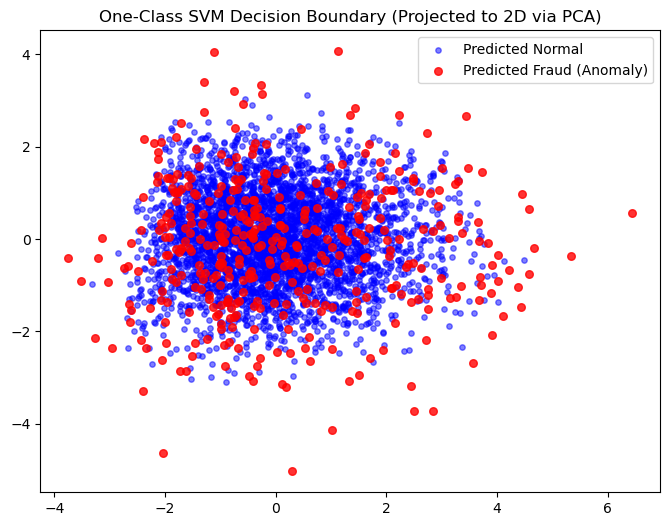

In [25]:
pca = PCA(n_components =2)
x_test_2d = pca.fit_transform(x_test)
preds = model.predict(x_test)
plt.figure(figsize=(8, 6))
plt.scatter(x_test_2d[preds == 1, 0], x_test_2d[preds==1, 1],
            color='blue', label='Predicted Normal', alpha=0.5, s = 15)
plt.scatter(x_test_2d[preds == -1, 0], x_test_2d[preds == -1, 1],
            color = 'red', label='Predicted Fraud (Anomaly)', alpha=0.8, s=30)
plt.title('One-Class SVM Decision Boundary (Projected to 2D via PCA)')
plt.legend()
plt.show()

### 7.2 Ground truth in 2D
The same projection colored by the true `is_fraud` label.

Fraud points are shifted toward the positive side of the first component, but most of them sit **inside the dense cluster** and not on its outer edge. The One-Class SVM's flags, in contrast, are spread across both sides, which helps explain why it catches fraud poorly. Two components compress a lot of information, so this is only a visual hint.

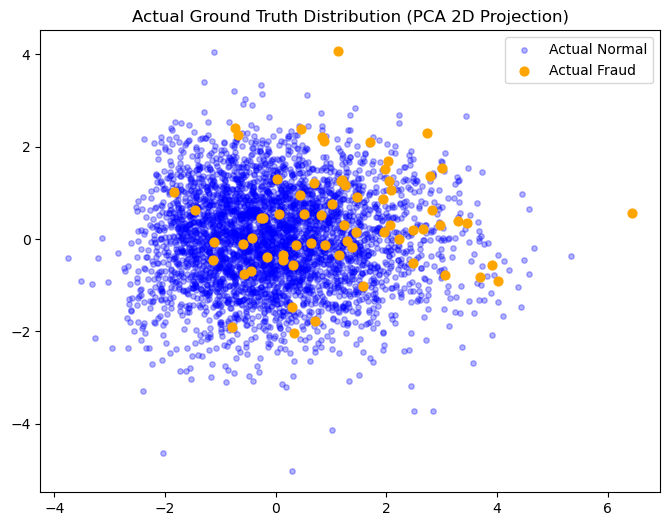

In [26]:
plt.figure(figsize=(8, 6))
plt.scatter(x_test_2d[y_test == 0, 0], x_test_2d[y_test == 0, 1], 
            color='blue', label='Actual Normal', alpha=0.3, s=15)
plt.scatter(x_test_2d[y_test == 1, 0], x_test_2d[y_test == 1, 1], 
            color='orange', label='Actual Fraud', alpha=1.0, s=40)
plt.title("Actual Ground Truth Distribution (PCA 2D Projection)")
plt.legend()
plt.show()

---

## 8. Model comparison: Isolation Forest and supervised baseline

The One-Class SVM result is weak, so two reference models are added to check whether the problem is the data or the model.

In [27]:
from sklearn.ensemble import IsolationForest, HistGradientBoostingClassifier

### 8.1 Isolation Forest
Also trained on normal transactions only, so it needs no fraud labels. It isolates points with random axis-aligned splits, and points that are isolated in few splits are more anomalous. The score is negated (`-score_samples`) so that higher means more anomalous.

In [28]:
iso = IsolationForest(n_estimators=300, random_state=42).fit(x_tr_norm)
iso_scores = -iso.score_samples(x_test)

### 8.2 Supervised reference
A `HistGradientBoostingClassifier` with `class_weight='balanced'`, trained on the **labeled** fitting set. It is not an anomaly detector: it uses the fraud labels and serves as a reference for how much signal the features contain.

In [29]:
clf = HistGradientBoostingClassifier(class_weight='balanced', random_state=42).fit(x_tr, y_tr)
sup_scores = clf.predict_proba(x_test)[:, 1]

c:\Users\DELL\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\Users\DELL\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "c:\Users\DELL\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\DELL\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^

### 8.3 Comparison on the test set

| Model | Uses fraud labels | ROC-AUC | PR-AUC |
|---|---|---|---|
| One-Class SVM | No | 0.787 | 0.070 |
| Isolation Forest | No | 0.875 | 0.182 |
| Gradient boosting (supervised) | Yes | 0.900 | 0.215 |

The no-skill PR-AUC is about 0.017.

In [30]:
for name , s in [('OCSVM', test_scores), ('IsoForest', iso_scores), ('Supervised', sup_scores)]:
    print(name, 'ROC-AUC', roc_auc_score(y_test, s), 'PR-AUC',average_precision_score(y_test, s))

OCSVM ROC-AUC 0.7868619472203937 PR-AUC 0.06969324348919528
IsoForest ROC-AUC 0.8745923343905213 PR-AUC 0.18247171150548508
Supervised ROC-AUC 0.900316408353779 PR-AUC 0.21473553727029612


---

## 9. Conclusions, limitations and next steps

### Conclusions

- **The One-Class SVM is the weak link, not the framing.** The Isolation Forest, which never sees fraud labels, reaches a PR-AUC of 0.18 (about 2.6 times the One-Class SVM and roughly 85% of the supervised model). So fraud in this data is reasonably detectable as a deviation from normal behavior.
- **Supervised learning wins, but only modestly** (PR-AUC 0.215 vs 0.182). With labels available it is the best option here, but the gap is small.
- **A plausible explanation for the One-Class SVM's weakness** (not tested here): it draws a radial, distance-based boundary in a space of about 25 features, while fraud appears shifted in one direction and sits mostly inside the dense cluster. Tree-based splits can pick out the few informative features instead.
- Absolute precision remains low for all models, so any real deployment would need a review step for flagged transactions.

### Limitations

- **Small test set:** only 68 fraud cases, from a single split. AUC and PR-AUC values are noisy, and the Isolation Forest vs supervised gap may be within noise.
- **Hyperparameters:** the final One-Class SVM uses the grid's `best_nu` but `gamma='scale'` instead of `best_gamma`, and the grid winner sits at the edge of the grid. The grid should be widened and the search repeated with cross-validation.
- **Isolation Forest and gradient boosting use default hyperparameters** and no threshold was chosen for them.
- **Variable reuse:** `scores` is assigned twice with opposite signs (negated in 6.2, raw in 6.5), so cells must be run in order.

### Next steps

- Widen the grid and use stratified cross-validation for model selection, and report results with confidence intervals (repeated splits or bootstrap).
- Tune the Isolation Forest, select a threshold for it, and compare precision at a fixed recall.
- Inspect feature importance (for example `permutation_importance`) to see which features drive detection.
- Try one-hot encoding in place of frequency encoding, and an autoencoder trained on normal data.
- Analyze the fraud cases that every model misses.